# Chương 3 — Market Basket Analysis (Local — Pure Julia)

Phiên bản chạy trực tiếp trên **máy local**, dùng thẳng mã nguồn `applications.jl` và `negFIN` tự viết của nhóm.

### Hướng dẫn chạy trên máy Local
1. Đảm bảo đã có file `data/chapter3/groceries.csv` trong dự án.
2. Chọn **Kernel: Julia** trong VS Code hoặc Jupyter.
3. Bấm **Run All** để chạy kiểm thử và sinh kết quả tại `results/chapter3/market_basket/`.

## Phần 1: Nạp Module `Applications` Từ Thư Mục Dự Án

In [1]:
using Pkg: Pkg

function find_project_root()::String
    dir = pwd()
    for _ in 1:4
        if isfile(joinpath(dir, "Project.toml")) &&
           isdir(joinpath(dir, "src", "applications"))
            return dir
        end
        parent = dirname(dir)
        parent == dir && break
        dir = parent
    end
    error("Không tìm thấy thư mục gốc chứa Project.toml")
end

const ROOT_DIR = find_project_root()
Pkg.activate(ROOT_DIR)
include(joinpath(ROOT_DIR, "src", "applications", "applications.jl"))
using .Applications: print_top_rules_table, run_market_basket
println("Julia version: ", VERSION)
println("Project root:  ", ROOT_DIR)

  Activating 

Julia version: 1

project at `~/Documents/Material/AI/DataMining/Frequent_Itemset_Mining`


.11.9
Project root:  /Users/nguyenthanhtung/Documents/Material/AI/DataMining/Frequent_Itemset_Mining


## Phần 2: Chạy Kiểm Thử Tự Động Chương 3

In [2]:
include(joinpath(ROOT_DIR, "tests", "test_ch3_julia.jl"))

MARKET: 4 transactions; 4 itemsets; 2 rules; support PASS; 0.065 sec


  [apple] => [milk]: confidence=66.7%, lift=0.89. Goi y thu nghiem ban kem; chi la tuong quan, khong chung minh quan he nhan qua.
  [milk] => [apple]: confidence=66.7%, lift=0.89. Goi y thu nghiem ban kem; chi la tuong quan, khong chung minh quan he nhan qua.
Output: /var/folders/8l/7prcmx5n5zzg53q7bzstcnzc0000gn/T/jl_1APafG/market
VISUAL: 36 train + 12 test images; 47 itemsets, 41 patterns; support PASS
Accuracy baseline=0.4167, with patterns=0.3333
Output: /var/folders/8l/7prcmx5n5zzg53q7bzstcnzc0000gn/T/jl_zRk7cH
Test Summary:                | Pass  Total  Time
Chapter 3 Julia applications |   27     27  8.1s


Test.DefaultTestSet("Chapter 3 Julia applications", Any[Test.DefaultTestSet("negFIN integration and support", Any[], 7, false, false, true, 1.795884320208755e9, 1.795884322460178e9, false, "/Users/nguyenthanhtung/Documents/Material/AI/DataMining/Frequent_Itemset_Mining/tests/test_ch3_julia.jl"), Test.DefaultTestSet("association rules and lift", Any[], 3, false, false, true, 1.795884322460247e9, 1.795884322706627e9, false, "/Users/nguyenthanhtung/Documents/Material/AI/DataMining/Frequent_Itemset_Mining/tests/test_ch3_julia.jl"), Test.DefaultTestSet("market input, output and naming", Any[], 5, false, false, true, 1.795884322706657e9, 1.795884325701206e9, false, "/Users/nguyenthanhtung/Documents/Material/AI/DataMining/Frequent_Itemset_Mining/tests/test_ch3_julia.jl"), Test.DefaultTestSet("repeatable visual descriptors and k-means", Any[], 5, false, false, true, 1.795884325701234e9, 1.795884326250464e9, false, "/Users/nguyenthanhtung/Documents/Material/AI/DataMining/Frequent_Itemset_Mining

## Phần 3: Chạy Phân Tích Giỏ Hàng & Xem Top-10 Luật Theo `Lift`

- Thay `algo=:optimized` thành `algo=:baseline` nếu muốn đối chứng hai phiên bản.
- Kết quả lưu tại `results/chapter3/market_basket/` (`summary.txt`, `top10_lift.csv`, `top10_lift.svg`, `association_rules.csv`).

MARKET: 9835 transactions; 333 itemsets; 322 rules; support PASS; 0.018 sec
  [curd] => [whole milk + yogurt]: confidence=18.9%, lift=3.37. Goi y thu nghiem ban kem; chi la tuong quan, khong chung minh quan he nhan qua.
  [whole milk + yogurt] => [curd]: confidence=18.0%, lift=3.37. Goi y thu nghiem ban kem; chi la tuong quan, khong chung minh quan he nhan qua.
  [citrus fruit + other vegetables] => [root vegetables]: confidence=35.9%, lift=3.30. Goi y thu nghiem ban kem; chi la tuong quan, khong chung minh quan he nhan qua.
Output: /Users/nguyenthanhtung/Documents/Material/AI/DataMining/Frequent_Itemset_Mining/results/chapter3/market_basket

=== MARKET BASKET SUMMARY ===
Source: /Users/nguyenthanhtung/Documents/Material/AI/DataMining/Frequent_Itemset_Mining/data/chapter3/groceries.csv
Transactions: 9835; products: 169
Algorithm: optimized; minsup: 0.01; minconf: 0.15
Frequent itemsets: 333; association rules: 322
Mining elapsed_sec: 0.0179
Support cross-check: PASS
Top 1: [curd] => [w

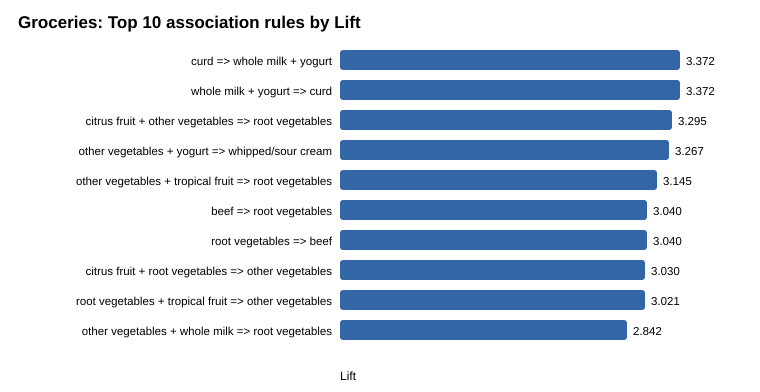

In [3]:
market_res = run_market_basket(;
    minsup=0.01,
    minconf=0.15,
    algo=:optimized,
)

market_dir = joinpath(ROOT_DIR, "results", "chapter3", "market_basket")
println("\n=== MARKET BASKET SUMMARY ===")
println(read(joinpath(market_dir, "summary.txt"), String))
println("=== TOP-10 LUẬT THEO LIFT ===")
print_top_rules_table(joinpath(market_dir, "top10_lift.csv"))
display("image/svg+xml", read(joinpath(market_dir, "top10_lift.svg"), String))